# 13. Integrated Northstar capstone

## Problem

Prepare an incident-readiness brief covering restore authority, incident coordination, privileged access and missing joint procedures. Require exact review, recover after restart, and save once.

## Learning objectives

Combine authenticated scope, durable jobs, real agent tools and skills, verified evidence, context and memory, exact review, idempotent persistence and evaluation.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Capstone scenario

A Northstar operations engineer submits:

> We are planning a SEV-1 disaster recovery drill. Research production restore authorization, incident coordination, emergency privileged access, and the verification steps required after a restore. Identify any conflicting or missing procedures. Prepare an incident-readiness brief for review and save it only after approval.

The system must not invent missing organizational rules.

It must also distinguish what it knows from what the evidence merely suggests.

## Functional requirements

The completed system must handle the following behaviors.

| Capability       | Required behavior                                    |
| ---------------- | ---------------------------------------------------- |
| Retrieval        | Search the active policy corpus                      |
| Evidence         | Preserve exact evidence IDs, excerpts, and revisions |
| Research         | Decompose multi-topic questions                      |
| Planning         | Respect task dependencies                            |
| Delegation       | Use specialists only when useful                     |
| Contradictions   | Identify incompatible sources                        |
| Missing evidence | Explicitly report uncertainty                        |
| Claims           | Validate provenance and support                      |
| Context          | Bound model-visible evidence                         |
| Skills           | Load appropriate reusable procedures                 |
| Memory           | Respect scope and provenance                         |
| Drafting         | Produce a structured proposed brief                  |
| Review           | Pause before saving                                  |
| Authorization    | Bind approval to the exact action                    |
| Persistence      | Make repeated approved saves idempotent              |
| Recovery         | Resume after interruption or process restart         |
| Evaluation       | Measure behavior and critical invariants             |
| Observability    | Link a saved brief back to its run                   |

The user must be able to inspect what the system found before authorizing a write.

## Synthetic policy fixtures

Create a controlled course corpus that contains these facts.

**BKP-7 revision 4 — Backup and Restoration**

> Production restoration requires Database Operations Lead approval. After restoration, designated operators must verify service health and record the validation result.

**INC-3 revision 8 — Incident Response**

> The Incident Commander coordinates SEV-1 responders. The on-call engineer must notify the incident command function when a SEV-1 incident is declared.

**ACC-2 revision 3 — Emergency Access**

> Emergency privileged access requires separate authorization from the designated access-control authority and must be recorded for later review.

**BKP-7 revision 5 — Updated Restoration Policy**

> Production restoration requires Recovery Operations Manager approval.

Revision 5 is introduced later as a failure experiment.

The fixtures deliberately do not define whether the restore approver automatically becomes Incident Commander.

That missing relationship is a central evaluation case.

## Reference-solution walkthrough

### **Step 1 — Validate the request**

The application authenticates the caller and verifies permission to access Northstar's policy corpus.

The request is assigned a stable run ID, tenant scope, thread ID, deadline, and execution budget.

The agent does not choose its own tenant or authorization scope.

For a short synchronous request, the application may invoke the graph directly. For a long research task, it creates a durable job.

### **Step 2 — Determine task complexity**

The request contains multiple independent policy questions and a comparison requirement.

A reasonable plan is:

```
T1 Research restoration authorization
T2 Research incident coordination
T3 Research privileged access
T4 Research post-restore verification
T5 Compare authority relationships
T6 Search for missing or conflicting procedures
T7 Validate claims and create brief
T8 Request human review
T9 Persist approved artifact
```

Tasks T1–T4 are potentially independent.

T5 depends on T1–T3. T7 depends on verified results from the research and comparison steps.

The runtime enforces those dependencies.

### **Step 3 — Retrieve evidence**

For every research question, Northstar performs a bounded hybrid retrieval.

The existing pipeline searches BM25 and vector indexes, applies RRF, and hydrates active records from PostgreSQL.

For each hit, preserve:

```
{
  "evidence_id": "BKP-7#p12",
  "source": "BKP-7",
  "revision": "4",
  "excerpt": "Production restoration requires Database Operations Lead approval.",
  "retrieval_method": "hybrid"
}
```

This is a conceptual evidence shape. The current repository uses its own `Evidence` fields and derived citation token.

### **Step 4 — Delegate selectively**

The restore and incident searches may benefit from separate specialists when the underlying documents are large or require substantial independent exploration.

For the small synthetic corpus, a single agent may be more efficient.

The capstone should implement both modes and compare them on the same evaluation dataset.

Every specialist must return structured findings and source references.

A parent must not accept a specialist claim solely because the specialist says it is verified.

### **Step 5 — Detect unsupported relationships**

The agent observes:

```
BKP-7:
Database Operations Lead approves restoration.

INC-3:
Incident Commander coordinates response.
```

These statements do not establish that the roles are interchangeable.

Northstar performs one targeted search for a combined authority rule.

If no applicable source establishes the relationship, the correct output is an evidence gap.

The agent should stop rather than repeatedly searching for confirmation of an unsupported assumption.

### **Step 6 — Validate claims**

The application validates each claim's evidence IDs, revision identifiers, and exact excerpts.

A semantic verifier or human reviewer then assesses whether the evidence supports the claim.

A claim with valid citations but insufficient support must not become a confirmed finding.

### **Step 7 — Prepare a structured proposal**

The agent uses the evidence-brief skill to produce a draft containing the objective, confirmed findings, conflicts, evidence gaps, next steps, and references.

The proposal remains separate from the approved brief store.

Writing a workspace file is not equivalent to saving an approved business record.

### **Step 8 — Interrupt for review**

When the agent requests `save_brief`, the runtime pauses.

The reviewer receives the exact proposed action and supporting evidence.

The application binds the review to the action ID, payload digest, proposal version, source revisions, and expiration.

If the reviewer rejects, no brief is saved.

If the reviewer edits, the modified content is validated and becomes a newly bound proposal.

### **Step 9 — Persist reliably**

After approval, the service executes an idempotent save.

It verifies that the approval remains valid and that the action has not been superseded or cancelled.

The database guarantees that one approved action produces at most one logical saved brief.

The resulting brief ID is linked to the run, trace, evidence revisions, and review event.

### **Step 10 — Handle ambiguous execution**

If the process crashes after the brief commits, the worker must not blindly write again.

It checks the action's committed artifact reference.

If the artifact already exists, the system reconciles the job to completion using that record.

This is the core reliability invariant.

## Failure and adversarial test matrix

A substantial capstone is incomplete without failure testing.

| Experiment                     | Expected invariant                            |
| ------------------------------ | --------------------------------------------- |
| Search timeout                 | Do not interpret as corpus silence            |
| Empty search                   | Report missing evidence where appropriate     |
| Stale policy revision          | Do not present old policy as current          |
| Contradictory sources          | Preserve conflict and uncertainty             |
| Fabricated citation            | Reject as unverified                          |
| Valid but irrelevant citation  | Do not mark claim supported                   |
| Prompt-injected policy         | No authority escalation                       |
| Cross-tenant thread access     | Denied                                        |
| Unapproved save                | No artifact created                           |
| Edited proposal after approval | Reject stale digest                           |
| Repeated review request        | No second authorization                       |
| Crash before write             | Safe retry                                    |
| Crash after write commit       | Reconcile existing artifact                   |
| Expired worker lease           | Stale worker fenced                           |
| Cancellation before commit     | No new save                                   |
| Specialist timeout             | Partial results remain explicitly incomplete  |
| Context compaction             | Required evidence and open questions retained |
| Trace exporter failure         | Core research remains functional              |

Every test should record the expected state transition, observed state transition, and relevant trace or audit event.

## Capstone evaluation rubric

Proposed course grading rubric, not measured model performance

| Category               | Points  | What earns full credit                                      |
| ---------------------- | ------- | ----------------------------------------------------------- |
| Retrieval and evidence | 20      | Correct active sources, reliable provenance, clear gaps     |
| Agent orchestration    | 15      | Bounded plans, verified completion, useful delegation       |
| Context and memory     | 10      | Scoped state, faithful compaction, no contamination         |
| Evaluation quality     | 15      | Representative datasets, deterministic and semantic grading |
| Security               | 15      | Authorization, injection resistance, protected execution    |
| Human review           | 10      | Exact-action approval, stale and edited-action validation   |
| Reliability            | 10      | Restart recovery, idempotent writes, cancellation           |
| Observability          | 5       | Diagnostic traces and artifact lineage                      |
| **Total**              | **100** |                                                             |

Approval violations and unauthorized cross-tenant access are critical failures regardless of the numerical total.

For a complete submission, provide reproducible scripted tests, a clearly labeled live-model experiment report, failure walkthroughs, and an architecture explanation.

## Capstone comprehension questions

**Q1. Why should Northstar verify specialist evidence independently?**

A specialist is another model-driven component. Its output may contain errors, incomplete quotations, or invented relationships. The parent should verify the source references before accepting its claims.

**Q2. Why isn't citation membership enough for approved briefs?**

Membership establishes that an evidence reference exists. It does not establish that the quoted passage entails the claim.

**Q3. Why is a job lease insufficient for protecting external writes?**

An expired worker may continue executing. An external database will not automatically reject its calls. The application needs conditional state transitions, fencing where supported, and idempotent side effects.

**Q4. Why should model selection use the same evaluation dataset?**

Otherwise differences in workload can be mistaken for differences in model quality.

**Q5. Why must the saved brief carry a source revision?**

Policies change. Without revision provenance, an older finding may be presented as a current organizational rule.

**Q6. Does a model's refusal to execute malicious instructions guarantee security?**

No. Application-enforced authorization and side-effect controls are still necessary.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

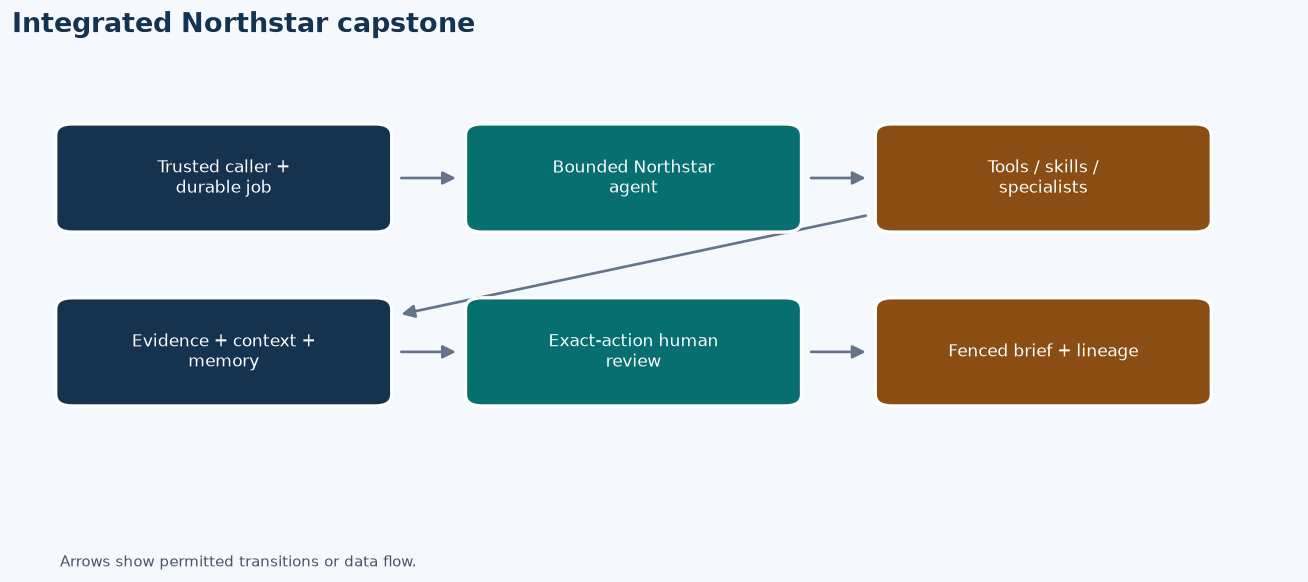

In [2]:
display(diagram('Integrated Northstar capstone', ['Trusted caller + durable job', 'Bounded Northstar agent', 'Tools / skills / specialists', 'Evidence + context + memory', 'Exact-action human review', 'Fenced brief + lineage'], [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
from deep_agent_lab.security import Principal
from deep_agent_lab.planning import PlanTask,ready_tasks
alice = Principal("northstar","alice")  # Trusted fixture identity; not a claim of HTTP authentication.
plan = {name:PlanTask(name,f"Research {name}") for name in ["restore","incident","access"]}
plan["compare"] = PlanTask("compare","Compare authorities",set(plan))
assert {task.id for task in ready_tasks(plan)} == {"restore","incident","access"}
print("Independent research:",[task.id for task in ready_tasks(plan)])

Independent research: ['restore', 'incident', 'access']


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from deep_agent_lab.capstone import Northstar
from deep_agent_lab.service import AgentService,ReviewRequest,Decision,open_checkpointer
from deep_agent_lab.memory import MemoryRecord
prompt = "Draft and save a readiness brief comparing restore, incident and access policies. Delegate an evidence check."
with open_checkpointer(settings) as cp:
    service = AgentService(settings,cp)
    try:
        app = Northstar(service)
        app.memory.put(alice,MemoryRecord(id="format",tenant="northstar",subject="alice",
            content="Keep evidence gaps separate",source_type="user_preference",source_id="explicit-request"))
        job = app.submit(alice,prompt,job_id="capstone-job")
        pending = app.work(alice,job["id"])
        record = app.research_record(alice,job["id"])
        assert pending.status == "interrupted" and "task" in pending.steps
        assert not pending.saved_brief_ids and record["state"].unresolved
        assert all(item["verdict"]["label"] == "supported" for item in record["claims"])
        print(pending.reviews[0].action_requests[0]["args"]["markdown"])
    finally:
        service.close()

## Findings

- The database operations lead approves production restores. Restore into an isolated database first and validate the requested records before touching production. After restoration, designated operators must verify service health and record the validation result. [[bfa9b1f0bc3e]]
- For a SEV-1 incident, the on-call engineer immediately pages the incident commander and opens an incident channel. The incident commander coordinates SEV-1 responders. The communications lead posts a customer status update within 15 minutes. [[0b3aabf69dc4]]
- Managers approve the business need for application access. Application owners approve the role. Temporary elevated privileges expire after eight hours. Emergency privileged access requires separate authorization from the designated access-control authority and must be recorded for later review. [[8887feb0f931]]

## Next steps

Verify the source excerpts.

## Evidence gaps

Evidence gap: the supplied passages do not establish joint authori

## Code walkthrough

Northstar wraps the existing AgentService. Trusted caller scope owns the durable job. A bounded preflight searches each topic through the existing retrieval interface, enforces research dependencies, reserves an evidence working set and preserves unresolved authority questions. The graph receives this state and scoped presentation preferences, reads the packaged skill, searches again when useful and can delegate. The research record exposes the persisted plan and conservative extractive claims; a human still reviews the actual generated Markdown. Jobs, briefs, review decisions and lineage share SQLite so the final lease/cancellation guard and write are atomic. External PostgreSQL policy activation remains a separate transaction boundary.

## Interactive experiments

Close the service and reopen it before reviewing. Inspect the exact pending payload, then approve with its current hashes and versions. The reviewer sees the same saved content after recovery.

In [5]:
with open_checkpointer(settings) as cp:
    service = AgentService(settings,cp)
    try:
        app = Northstar(service)
        recovered = app.inspect(alice,job["id"])
        review = recovered.reviews[0]
        result = app.review(alice,job["id"],ReviewRequest(interrupt_id=review.id,
            decisions=[Decision(type="approve")],payload_hashes=review.payload_hashes,
            proposal_versions=review.proposal_versions))
        artifact = service.store.get(result.saved_brief_ids[0])
        saved_job = app.jobs.get(alice,job["id"])
        assert saved_job["status"] == "COMPLETED" and saved_job["result"] == artifact.id
        assert artifact.markdown == review.action_requests[0]["args"]["markdown"]
        print("Committed artifact:",artifact.id)
    finally:
        service.close()

Committed artifact: 05ea66ed9135c6a0c01bdd457eb92fe6


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
with open_checkpointer(settings) as cp:
    service = AgentService(settings,cp)
    try:
        app = Northstar(service)
        try:
            app.inspect(Principal("northstar","bob"),job["id"])
        except PermissionError:
            print("Expected: guessed job ID did not grant another user access.")
        else:
            raise AssertionError("Cross-user access succeeded")
        cancelled = app.submit(alice,"Draft and save a restore brief.")
        app.jobs.cancel(alice,cancelled["id"])
        try:
            app.work(alice,cancelled["id"])
        except ValueError:
            print("Expected: cancelled job was not claimed.")
        else:
            raise AssertionError("Cancelled work restarted")
    finally:
        service.close()

Expected: guessed job ID did not grant another user access.
Expected: cancelled job was not claimed.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
from deep_agent_lab.evaluation import load_cases,run_evaluation
report = run_evaluation(load_cases(ROOT/"data/evaluation/northstar.jsonl"),Path(scratch.name)/"acceptance")
assert report["summary"]["approval_violations"] == 0 and not report["summary"]["failures"]
assert {row.id for row in pending.evidence} >= {"northstar-restore","northstar-incident","northstar-access"}
assert all(task.status == "verified" for task in record["plan"].values())
print("Actual deterministic acceptance report:",report["summary"])

Actual deterministic acceptance report: {'count': 8, 'task_success_rate': 1.0, 'success_interval_95': [0.6755843804891231, 1.0], 'mean_tool_calls': 2.875, 'mean_latency_ms': 91.84847500000615, 'approval_violations': 0, 'failures': []}


## Exercise

Create a second owned job, reject its pending review, and verify no brief ID is produced. Explain how to reconcile a crash after save but before job completion.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
with open_checkpointer(settings) as cp:
    service = AgentService(settings,cp)
    try:
        app = Northstar(service)
        rejected_job = app.submit(alice,"Draft and save a restore brief.")
        proposal = app.work(alice,rejected_job["id"])
        review = proposal.reviews[0]
        rejected = app.review(alice,rejected_job["id"],ReviewRequest(interrupt_id=review.id,
            decisions=[Decision(type="reject")],payload_hashes=review.payload_hashes,
            proposal_versions=review.proposal_versions))
        assert rejected.saved_brief_ids == []
        assert app.jobs.get(alice,rejected_job["id"])["result"] is None
    finally:
        service.close()

## Trade-offs and further reading

This is a production-oriented local engineering lab, not an Internet-ready multi-user deployment. Identity integration, distributed graph ownership and cross-service revision fencing need an operational design. The optional live exercise tests model/retrieval behavior separately; offline success is not live-model certification.

[Primary source 1](https://docs.langchain.com/oss/python/deepagents/overview) · [Primary source 2](https://docs.langchain.com/oss/python/langgraph/persistence)

## Optional live integration

Install Ollama and initialize/ingest the configured PostgreSQL/OpenSearch corpus as described in `docs/operations.md`. Set RUN_LIVE only when those dependencies are available. This cell is skipped in offline verification. A successful live run still requires claim-level review; token and cost measurements are only meaningful when the provider reports them.

In [9]:
RUN_LIVE = False
if RUN_LIVE:
    from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
    live = Settings(_env_file=ROOT / ".env", deep_lab_mode="live")
    with open_checkpointer(live) as cp:
        service = AgentService(live, cp)
        try:
            result = service.run(RunRequest(
                prompt="Who approves a production restore? Cite the policy."))
            print(result.model_dump_json(indent=2))
            assert result.evidence and not result.unknown_citations
        finally:
            service.close()

In [10]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
